# N155 · Does clip order change the value of historical replay?

**Local BDD100K development experiment.** The N106 reserved stream and its original
learner/Adam checkpoint were unavailable here. This run reconstructs the ordering
design using an earlier archive of real highway videos and an earlier BDD-warm
RGB64 TinyViT MAE with a fresh, common AdamW optimizer. The selected videos are
from BDD's original test split and were designated as development streams in the
local archive. These data have been used for development and capture-session
independence is unknown. Lighting is the archived keyframe's metadata.

Each of two clip-disjoint pools has 20 clips. The structured order is five day,
five night, five day, five night. Two independently seeded permutations shuffle
the 17-clip suffix. All three orders share the first three clips to match the
288-arrival fill and the set of clips eligible for updates. Every clip retains
96 chronological source frames from stride two, approximately 15 frames/s on
30-fps video. Both orders keep within-clip correlation and change which clips
are adjacent. The contrast therefore measures an ordering effect under this
construction, including changes in regime dwell time and individual clip adjacency.

| Memory policy | Five gradient images per update |
|---|---|
| Current | Five independent views of the current frame |
| FIFO | One current view and four distinct uniform draws from the prior 256 frames |
| History | One current view and four distinct uniform draws from a 256-slot Algorithm R reservoir |

Each update assigns half the loss weight to the first view and half to the four
other views. All 36 trajectories use 1,632 updates, 8,160 gradient images and a
fixed learning rate of 0.000025. Training draws are paired by arrival position.
Every trajectory starts from the same warm weights. No health or task result
selects training actions. The memory intervention is fixed retention policy.

**Primary contrast.** At each of the 17 post-fill clip boundaries, measure
reconstruction on the same eight audit-only clips, using eight frames per clip
and two fixed masks. Average loss over boundaries and equally over lighting.
Historical replay benefit is FIFO loss minus history loss. The interaction is
that benefit in blocked order minus its mean across the two shuffled orders.
Positive interaction favors historical replay more under the blocked schedule.
Average training seeds within each pool, then weight the two pools equally.
Report all pool/seed pairs. Frames, checkpoints, seeds and shuffles within one
pool share clips, so they do not supply independent population replication.

**Secondary readouts.** Day/night loss, RankMe, sampled pre-update arrival loss
and first-32-frame loss after lighting switches, replay age and cross-lighting
share, and final balanced scene-probe accuracy on the archived BDD validation
panel. Scene probes fit only on the three fixed supports. The primary audit and
validation pixels are checked for exact overlap with training. Historical replay
can change age, coverage and diversity together. Audit reconstruction measures
SSL health. The scene probe separately measures task readout.


## Live results

**complete** · All matched trajectories verified

Updated UTC `2026-11-06T12:03:14+00:00` · PID `29008` · **36/36** trajectories · **58,752/58,752** committed optimizer updates.

[Open the auto-refreshing view while training](http://127.0.0.1:8855/). This notebook is also written to disk at every committed clip.

Warm audit loss 0.82303 · Warm balanced scene accuracy 41.22%.

### Matched order interaction

Positive values favor history more under the blocked order. Each row requires all three complete FIFO/history pairs.

| Pool / seed | Blocked gain | Shuffle 1 gain | Shuffle 2 gain | Balanced interaction | Day interaction | Night interaction | Final probe interaction (pp) |
|---|---:|---:|---:|---:|---:|---:|---:|
| pool_1 / 15501 | +0.020338 | +0.008796 | +0.023396 | +0.004242 | +0.001546 | +0.006938 | -1.694 |
| pool_1 / 15507 | +0.018147 | +0.013769 | +0.023327 | -0.000401 | -0.005323 | +0.004521 | -0.944 |
| pool_2 / 15501 | +0.005799 | +0.005629 | +0.006438 | -0.000235 | +0.002794 | -0.003263 | -0.500 |
| pool_2 / 15507 | +0.007254 | +0.007062 | +0.006943 | +0.000251 | +0.004182 | -0.003679 | -2.028 |

Equal-pool primary estimate **+0.000964**. Pool means pool_1 +0.001920, pool_2 +0.000008.

### Trajectories

Partial values reflect each arm's latest committed boundary.

| Pool / order / seed / arm | Updates | Audit loss D / N | RankMe D / N | Switch pre-loss | Mean replay age | Cross-light / older share | Final scene accuracy |
|---|---:|---:|---:|---:|---:|---:|---:|
| pool_1 / blocked / 15501 / current | 1,632 | 0.9435 / 0.8858 | 2.53 / 2.39 | 0.9307 | — | — | 40.78% |
| pool_1 / blocked / 15501 / fifo | 1,632 | 0.8740 / 0.8334 | 2.40 / 2.77 | 0.9189 | 129 | 23.9% / 0.0% | 42.06% |
| pool_1 / blocked / 15501 / history | 1,632 | 0.7928 / 0.8206 | 2.19 / 3.06 | 0.9085 | 552 | 48.2% / 69.6% | 40.06% |
| pool_1 / shuffle_1 / 15501 / current | 1,632 | 0.8656 / 0.8970 | 1.83 / 2.46 | 0.9036 | — | — | 40.61% |
| pool_1 / shuffle_1 / 15501 / fifo | 1,632 | 0.8254 / 0.8710 | 1.98 / 2.75 | 0.8743 | 129 | 40.2% / 0.0% | 41.56% |
| pool_1 / shuffle_1 / 15501 / history | 1,632 | 0.7987 / 0.8562 | 2.02 / 3.97 | 0.8604 | 552 | 53.3% / 69.6% | 41.00% |
| pool_1 / shuffle_2 / 15501 / current | 1,632 | 0.7879 / 0.8718 | 1.86 / 2.86 | 0.9027 | — | — | 41.61% |
| pool_1 / shuffle_2 / 15501 / fifo | 1,632 | 0.7957 / 0.8690 | 2.01 / 4.18 | 0.8718 | 129 | 41.7% / 0.0% | 41.61% |
| pool_1 / shuffle_2 / 15501 / history | 1,632 | 0.7735 / 0.8349 | 2.11 / 4.14 | 0.8626 | 552 | 49.2% / 69.6% | 41.56% |
| pool_2 / blocked / 15501 / current | 1,632 | 0.8133 / 0.8477 | 2.05 / 2.26 | 0.7676 | — | — | 41.61% |
| pool_2 / blocked / 15501 / fifo | 1,632 | 0.8254 / 0.8258 | 1.97 / 2.50 | 0.7132 | 129 | 23.9% / 0.0% | 40.39% |
| pool_2 / blocked / 15501 / history | 1,632 | 0.7571 / 0.8235 | 2.10 / 2.59 | 0.7128 | 552 | 48.2% / 69.6% | 40.17% |
| pool_2 / shuffle_1 / 15501 / current | 1,632 | 0.9076 / 0.8808 | 2.25 / 2.08 | 0.8016 | — | — | 40.72% |
| pool_2 / shuffle_1 / 15501 / fifo | 1,632 | 0.7581 / 0.8271 | 2.27 / 2.80 | 0.7846 | 129 | 32.5% / 0.0% | 39.28% |
| pool_2 / shuffle_1 / 15501 / history | 1,632 | 0.7559 / 0.8220 | 2.44 / 2.52 | 0.7699 | 552 | 47.9% / 69.6% | 40.56% |
| pool_2 / shuffle_2 / 15501 / current | 1,632 | 0.7717 / 0.8473 | 1.75 / 2.65 | 0.8085 | — | — | 41.61% |
| pool_2 / shuffle_2 / 15501 / fifo | 1,632 | 0.7611 / 0.8313 | 2.15 / 2.82 | 0.7845 | 129 | 49.7% / 0.0% | 41.17% |
| pool_2 / shuffle_2 / 15501 / history | 1,632 | 0.7549 / 0.8237 | 1.99 / 2.76 | 0.7802 | 552 | 53.0% / 69.6% | 40.44% |
| pool_1 / blocked / 15507 / current | 1,632 | 0.9642 / 0.8888 | 2.39 / 2.37 | 0.9323 | — | — | 40.89% |
| pool_1 / blocked / 15507 / fifo | 1,632 | 0.8780 / 0.8331 | 2.35 / 2.91 | 0.9191 | 128 | 23.7% / 0.0% | 42.33% |
| pool_1 / blocked / 15507 / history | 1,632 | 0.7878 / 0.8244 | 2.17 / 3.06 | 0.9090 | 563 | 48.6% / 69.3% | 41.33% |
| pool_1 / shuffle_1 / 15507 / current | 1,632 | 0.8773 / 0.8999 | 1.84 / 2.41 | 0.8993 | — | — | 40.67% |
| pool_1 / shuffle_1 / 15507 / fifo | 1,632 | 0.8359 / 0.8780 | 2.03 / 2.63 | 0.8773 | 128 | 40.9% / 0.0% | 41.56% |
| pool_1 / shuffle_1 / 15507 / history | 1,632 | 0.8010 / 0.8625 | 2.03 / 4.18 | 0.8652 | 563 | 53.2% / 69.3% | 41.22% |
| pool_1 / shuffle_2 / 15507 / current | 1,632 | 0.7867 / 0.8810 | 1.81 / 2.76 | 0.8951 | — | — | 41.50% |
| pool_1 / shuffle_2 / 15507 / fifo | 1,632 | 0.7943 / 0.8488 | 1.91 / 4.33 | 0.8754 | 128 | 41.5% / 0.0% | 41.33% |
| pool_1 / shuffle_2 / 15507 / history | 1,632 | 0.7720 / 0.8365 | 2.12 / 4.19 | 0.8634 | 563 | 49.7% / 69.3% | 41.56% |
| pool_2 / blocked / 15507 / current | 1,632 | 0.8220 / 0.8485 | 2.05 / 2.25 | 0.7787 | — | — | 41.22% |
| pool_2 / blocked / 15507 / fifo | 1,632 | 0.8258 / 0.8309 | 1.95 / 2.43 | 0.7171 | 128 | 23.7% / 0.0% | 40.44% |
| pool_2 / blocked / 15507 / history | 1,632 | 0.7551 / 0.8249 | 2.08 / 2.57 | 0.7113 | 563 | 48.6% / 69.3% | 39.50% |
| pool_2 / shuffle_1 / 15507 / current | 1,632 | 0.8919 / 0.8830 | 2.34 / 2.08 | 0.7974 | — | — | 40.17% |
| pool_2 / shuffle_1 / 15507 / fifo | 1,632 | 0.7622 / 0.8264 | 2.29 / 2.82 | 0.7820 | 128 | 32.2% / 0.0% | 38.28% |
| pool_2 / shuffle_1 / 15507 / history | 1,632 | 0.7553 / 0.8203 | 2.48 / 2.53 | 0.7678 | 563 | 47.2% / 69.3% | 40.44% |
| pool_2 / shuffle_2 / 15507 / current | 1,632 | 0.7673 / 0.8481 | 1.75 / 2.65 | 0.8108 | — | — | 41.89% |
| pool_2 / shuffle_2 / 15507 / fifo | 1,632 | 0.7588 / 0.8299 | 2.25 / 3.08 | 0.7848 | 128 | 49.8% / 0.0% | 40.72% |
| pool_2 / shuffle_2 / 15507 / history | 1,632 | 0.7518 / 0.8275 | 2.01 / 2.60 | 0.7806 | 563 | 52.2% / 69.3% | 40.72% |

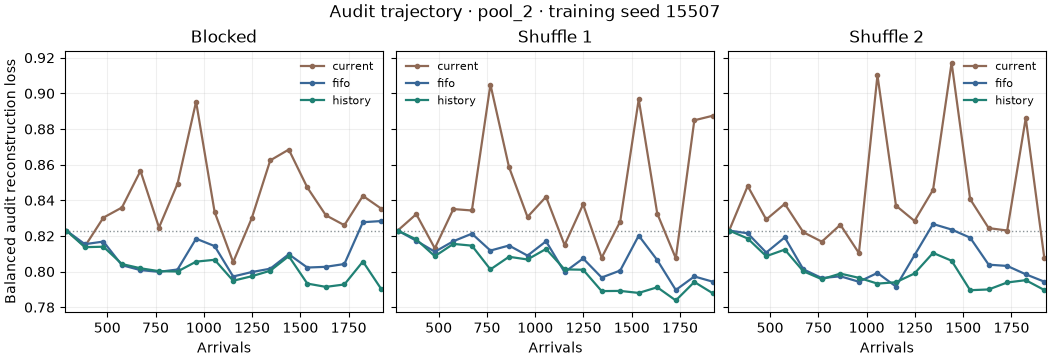

## Frozen clip order

D is day, N is night. The first three clips are shared within each pool.

| Pool | Order | Lighting by clip | Switches |
|---|---|---|---:|
| pool_1 | blocked | `D D D D D N N N N N D D D D D N N N N N` | 3 |
| pool_1 | shuffle_1 | `D D D N N N N N D N D N D D D N D N D N` | 11 |
| pool_1 | shuffle_2 | `D D D D D N N N D N D N N N D N D N N D` | 10 |
| pool_2 | blocked | `D D D D D N N N N N D D D D D N N N N N` | 3 |
| pool_2 | shuffle_1 | `D D D D D N N N D D D D N N N N N D N N` | 5 |
| pool_2 | shuffle_2 | `D D D N N D N D N D N N D N D N N D N D` | 14 |